# Aperture Photometry Example

Following in part this series of tutorials by [Micah Laing](https://www.youtube.com/@mic_n_ike)
This uses the photulils package, which is part of astropy: https://photutils.readthedocs.io/en/stable/

1. [Astropy Lesson 1: Introduction to FITS File Handling](https://www.youtube.com/watch?v=_DzSIeruotQ) - I didn't do the start of this as using a different Jupyter Hub.
2. [Astropy Lesson 2: Photutils.detection](https://www.youtube.com/watch?v=vxMoG2K_n5o)
3. [Astropy Lesson 3: Aperture Photometry](https://www.youtube.com/watch?v=8162hq_5ZkQ) - didn't do the end as it's about calibration of HST images. 

I didn't need to install things because I did it on a [SciServer Astronomy](https://www.sciserver.org/) Compute Image. All the import statements also work on `python3.10.10` kernel on the Haverford Jupyter Hub (as of Nov 2024).

Last updated Oct 2026

- Karen Masters (for ASTR341 Class). 

First: 
1. Use AIJ to calibrate and align the two filters of images for your cluster (if using this for cluster photometry). 
Optional: You can WCS solve and then you can use SkyApertures. 
2. Don't forget to align the two median aligned images (you want the stars in the same pixel in both images to make the below easier)
3. Measure the size of a star in pixels (use AIJ to tell you the optimal aperture to use). You get a plot like this.
<img src="PerseusClusterData/Seeing_Profile_rband.png" width="300">

4. You then need to put the aligned calibrated fits images on the server you are running this code on....

I actually had three filters, so I made a three colour image of NGC844! The Double Cluster (h and χ Persei) is both NGC 869 and NGC 884, but only one fits in our CCD field of view at once. 

<img src="PerseusClusterData/RGB_NGC884.jpg" width="500">



In [42]:
import numpy as np

from astropy.io import fits

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm #Capitals matter

from astropy.stats import sigma_clipped_stats, SigmaClip

from photutils.detection import DAOStarFinder
from photutils.aperture import CircularAperture, CircularAnnulus
#from photoutils.aperture import AperturePhotometry #Only in later version of photutils
from photutils.aperture import aperture_photometry #I found that Aperture_photometry is now photometry. I can't get ApertureStars to load

from photutils.background import Background2D, MedianBackground


In [27]:
#Note the version of photutils matters. 
%pip show photutils

Name: photutils
Version: 1.2.0
Summary: An Astropy package for source detection and photometry
Home-page: https://github.com/astropy/photutils
Author: Photutils Developers
Author-email: photutils.team@gmail.com
License: BSD 3-Clause
Location: /home/idies/miniconda3/envs/py38/lib/python3.8/site-packages
Requires: astropy, numpy
Required-by: 
Note: you may need to restart the kernel to use updated packages.


In [3]:
fits_file = fits.open('PerseusClusterData/ngc869_MED_aligned_r.fits')
image_data=fits_file[0].data

In [4]:
#This is just an array of numbers
print(image_data)

[[ 33.   45.5  34.5 ...   0.    0.    0. ]
 [ 91.  105.   86.5 ...   0.    0.    0. ]
 [ 96.   99.5 105.5 ...  45.   41.    0. ]
 ...
 [ 97.5  82.   89.  ...  51.5  46.5   0. ]
 [109.   87.   85.5 ...  49.   52.    0. ]
 [104.5  94.   84.  ...  43.5  42.    0. ]]


In [5]:
#So you can do stats
print('Min: ', np.min(image_data))
print('Max: ', np.max(image_data))

Min:  0.0
Max:  58305.0


Text(0, 0.5, 'Number of pixels')

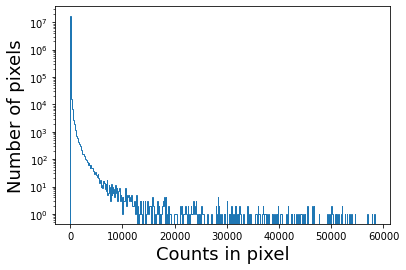

In [7]:
#Or plot a histogram. Easier to do this if you flatten the 2D array into a single array.
plt.hist(image_data.flatten(),histtype='step',bins=500)
plt.yscale('log')
plt.xlabel('Counts in pixel',fontsize=18)
plt.ylabel('Number of pixels',fontsize=18)

# Make an image
https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html

<function matplotlib.pyplot.show(close=None, block=None)>

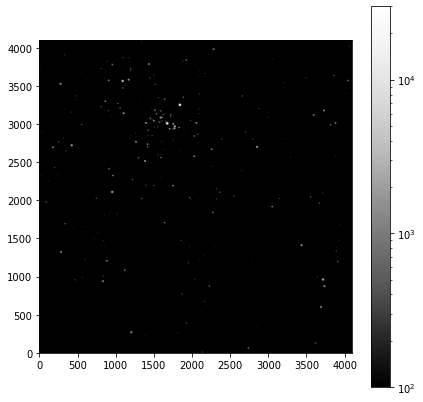

In [11]:
#You can make an image 
plt.figure(figsize=(7,7))
plt.imshow(image_data,origin='lower',norm=LogNorm(vmin=100,vmax=30000),cmap='Greys_r') #Greys_r inverts the scale
plt.colorbar()
plt.show

### You can select a section of the image

<function matplotlib.pyplot.show(close=None, block=None)>

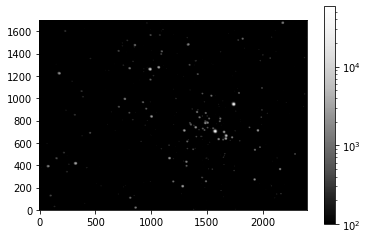

In [12]:
section1 = image_data[2300:4000, 100:2500]
plt.figure()
plt.imshow(section1,origin='lower',norm=LogNorm(vmin=100),cmap='Greys_r')
plt.colorbar()
plt.show

## Using DAO Star Finder

This can find all the point sources in your image. I did the entire image below. You could do just a section if your cluster is all in one part of the image. 

Sigma clip the data first to removes extreme outlier (saturatued pixels) and find the stars better. 

In [29]:
mean,median,std=sigma_clipped_stats(image_data,sigma=3.0)
print('Mean, Median, standard deviation (in counts):', mean,median,std)

Mean, Median, standard deviation (in counts): 83.78502 83.5 6.4192123


In [30]:
daofind=DAOStarFinder(fwhm=8.0,threshold=8.0*std) #FWHM = 7.96 is the measured value of our image
sources=daofind(image_data-median)

for col in sources.colnames:
    if col not in ('id','npix'):
        sources[col].info.format='%.2f'
        
sources.pprint(max_width=76)

 id xcentroid ycentroid sharpness roundness1 ... sky   peak   flux  mag 
--- --------- --------- --------- ---------- ... ---- ------ ----- -----
  1    294.14      5.18      0.69      -0.06 ... 0.00  15.00  1.06 -0.06
  2    353.95      5.25      0.30      -0.26 ... 0.00   1.50  1.00 -0.00
  3    706.55      6.51      0.49      -0.43 ... 0.00  45.50  1.55 -0.48
  4   1407.17      4.78      0.34      -0.49 ... 0.00   7.00  1.19 -0.19
  5   2288.25      6.63      0.47      -0.63 ... 0.00  48.50  1.39 -0.35
  6   2557.71      4.37      0.37      -0.42 ... 0.00   7.00  1.06 -0.07
  7   2905.54      4.72      0.33      -0.26 ... 0.00   7.00  1.18 -0.18
  8   3281.74      4.53      0.22      -0.03 ... 0.00   4.50  1.26 -0.25
  9   3348.31      5.46      0.64      -0.31 ... 0.00  14.00  1.01 -0.02
 10   3403.94      5.42      0.23      -0.42 ... 0.00   1.50  1.03 -0.03
...       ...       ...       ...        ... ...  ...    ...   ...   ...
690    134.16   4003.85      0.37      -0.50 ... 0.

### Overlay Apertures on Detected Stars

In [31]:
positions=np.transpose((sources['xcentroid'],sources['ycentroid'])) #Because python does yx.
apertures = CircularAperture(positions,r=15.0) # This is the 1.5 FWHM as measured from the image using AIJ

<function matplotlib.pyplot.show(close=None, block=None)>

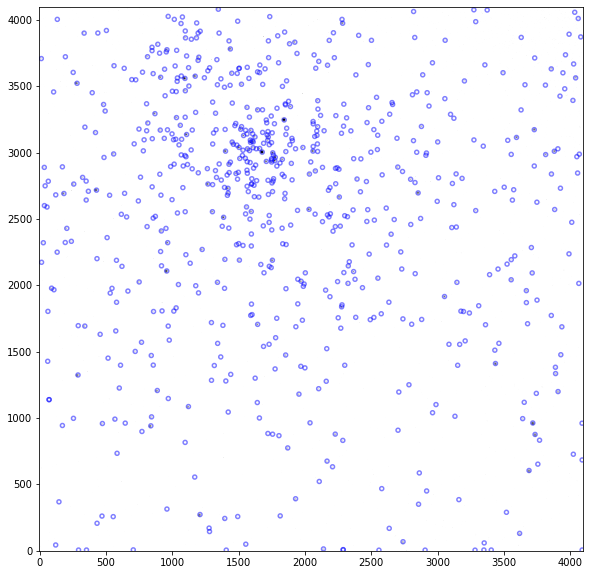

In [32]:
plt.figure(figsize=(10,10))
plt.imshow(image_data,origin='lower',norm=LogNorm(vmin=100,vmax=20000),cmap='Greys',interpolation = 'nearest')
apertures.plot(color='blue',lw=1.5,alpha=0.5);

#plt.colorbar()
plt.show

# Aperture Photometry

Goal here it to make a sky aperture around each star to subtract the background. 

## Making an Annulus for the Background

First step is easy - just using the radii recommended by AIJ

In [33]:
annulus_aperture = CircularAnnulus(positions, r_in=27, r_out=41) # Set these to the ideal innder and outer apertures. 

<function matplotlib.pyplot.show(close=None, block=None)>

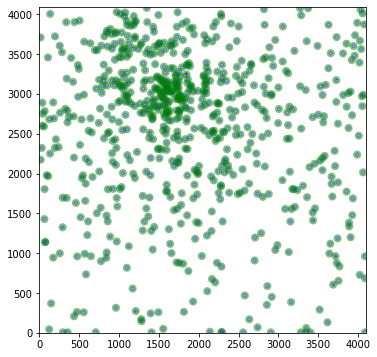

In [34]:
plt.figure(figsize=(10,6))
plt.imshow(image_data,origin='lower',norm=LogNorm(vmin=100,vmax=30000),cmap='Greys',interpolation = 'nearest')
apertures.plot(color='blue',lw=1.5,alpha=0.5);
annulus_aperture.plot(color='green',lw=1.5,alpha=0.5)
#plt.colorbar()
plt.show

In [35]:
star_data = aperture_photometry(image_data,apertures)

In [36]:
bkg = aperture_photometry(image_data,annulus_aperture)
bkg_area = annulus_aperture.area_overlap(image_data)
aperture_area = apertures.area_overlap(image_data)
bkg_total = (bkg['aperture_sum']/bkg_area)*aperture_area #deals with different sizes of the apertures

In [37]:
star_data['total_bkg']=bkg_total
star_data['bkg_area']=bkg_area
star_data['aperture_area']=aperture_area
star_data['star_count']=star_data['aperture_sum']-star_data['total_bkg']


for col in star_data.colnames:
    star_data[col].info.format='%.8g'

star_data.pprint

<bound method Table.pprint of <QTable length=700>
  id   xcenter   ycenter  aperture_sum ...  bkg_area aperture_area star_count
         pix       pix                 ...                                   
int64  float64   float64    float64    ...  float64     float64     float64  
----- --------- --------- ------------ ... --------- ------------- ----------
    1 294.14426 5.1827858    40601.969 ... 1655.3007     519.74188   -1180.61
    2 353.95453  5.248586    41071.395 ...  1657.171     521.56695 -883.51809
    3 706.54616 6.5100303    51495.987 ... 1693.1628     555.80233  7272.3305
    4 1407.1687 4.7839498    39723.421 ... 1643.9782     508.60535 -1234.3219
    5 2288.2457 6.6256883    55072.006 ...  1696.477     558.86273  9450.8598
    6 2557.7091 4.3654899    39513.247 ... 1632.1224      496.7923 -963.70305
    7 2905.5385 4.7208711    40555.978 ... 1642.1896      506.8328 -1146.4602
    8 3281.7422 4.5324234    40163.112 ... 1636.8492     501.51986 -1962.7791
    9 3348.309

### Raw Instrumental Magnitudes of Sources and Background. 

Background done this way has stars in it - not ideal. 

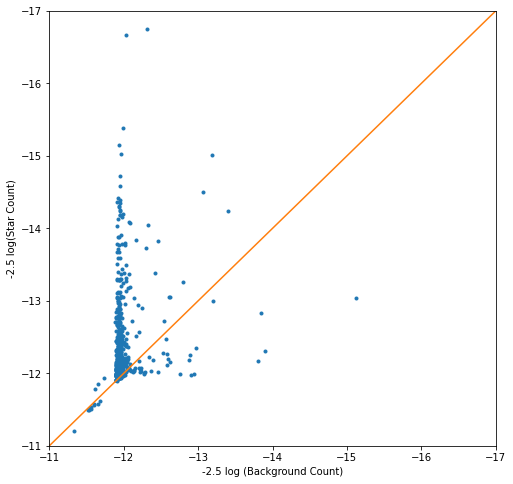

In [38]:
plt.figure(figsize=(8,8))
plt.plot(-2.5*np.log10(star_data['total_bkg']),-2.5*np.log10(star_data['aperture_sum']),'.')
plt.plot([-17,-11],[-17,-11])
plt.ylim(-11,-17)
plt.xlim(-11,-17)
plt.ylabel('-2.5 log(Star Count)')
plt.xlabel('-2.5 log (Background Count)')
plt.show()


### A Better Background

Photutils has techniques to estimate background. https://photutils.readthedocs.io/en/stable/user_guide/background.html#

In [54]:
#Text from the photutils background page: 
#We start by creating a Background2D object using a box size of 15x15 and a 3x3 median filter. 
#We will estimate the background level in each mesh as the sigma-clipped median using an instance of 
#MedianBackground:
#KLM edits - when I did this the background had obvious stars in it. I made the box size larger, 
# and sigmaclip lower to remove more
sigma_clip = SigmaClip(sigma=2.0)
bkg_estimator = MedianBackground()
bkg = Background2D(image_data, (30, 30), filter_size=(6, 6),
                   sigma_clip=sigma_clip, bkg_estimator=bkg_estimator)

In [55]:
#vThe global median value of the low-resolution background and background RMS image can be accessed with 
# the background_median and background_rms_median attributes, respectively:
print(bkg.background_median)

83.27323980169066


In [56]:
print(round(bkg.background_rms_median, 4))

4.8742


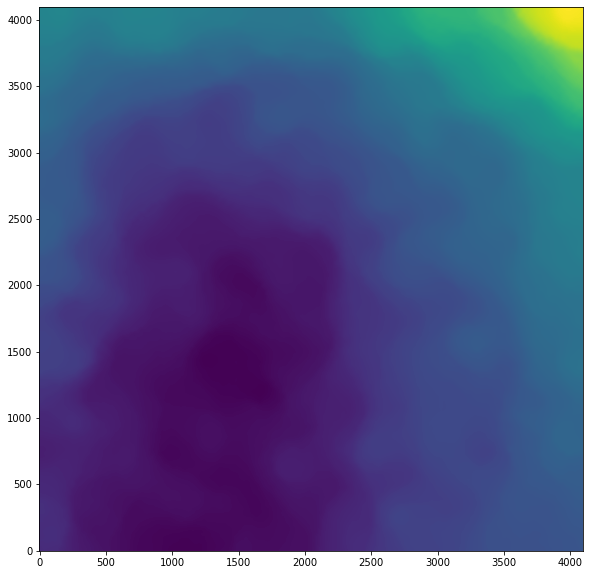

In [57]:
# Plot the background
fig, ax = plt.subplots(figsize=(10,10))
ax.imshow(bkg.background, origin='lower')

In [59]:
#Now just use the star apertures to measure background on the background image
#star_data = aperture_photometry(image_data,apertures)
bkg2 = aperture_photometry(bkg.background,apertures)

In [62]:
star_data['better_bkg']=bkg2['aperture_sum']
star_data['better_star_count']=star_data['aperture_sum']-star_data['better_bkg']

for col in star_data.colnames:
    star_data[col].info.format='%.8g'

star_data.pprint

<bound method Table.pprint of <QTable length=700>
  id   xcenter   ycenter  ... star_count better_bkg better_star_count
         pix       pix    ...                                        
int64  float64   float64  ...  float64    float64        float64     
----- --------- --------- ... ---------- ---------- -----------------
    1 294.14426 5.1827858 ...   -1180.61  42433.579        -1831.6096
    2 353.95453  5.248586 ... -883.51809  42523.467        -1452.0719
    3 706.54616 6.5100303 ...  7272.3305  45029.376         6466.6109
    4 1407.1687 4.7839498 ... -1234.3219  41188.881        -1465.4605
    5 2288.2457 6.6256883 ...  9450.8598  45852.074         9219.9325
    6 2557.7091 4.3654899 ... -963.70305  41042.816        -1529.5694
    7 2905.5385 4.7208711 ... -1146.4602  42107.981        -1552.0033
    8 3281.7422 4.5324234 ... -1962.7791  41852.651        -1689.5388
    9 3348.3093 5.4595946 ... -737.66676  44069.864        -1132.2733
  ...       ...       ... ...        ...

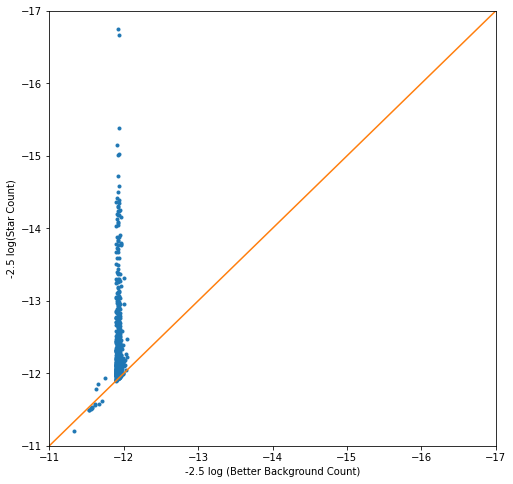

In [63]:
plt.figure(figsize=(8,8))
plt.plot(-2.5*np.log10(star_data['better_bkg']),-2.5*np.log10(star_data['aperture_sum']),'.')
plt.plot([-17,-11],[-17,-11])
plt.ylim(-11,-17)
plt.xlim(-11,-17)
plt.ylabel('-2.5 log(Star Count)')
plt.xlabel('-2.5 log (Better Background Count)')
plt.show()

### Instrumental Magnitudes

These are just -2.5 log10 (counts)

You can't do it for when the background is greater than the star flux - so quick method is to just ignore those. 

In [65]:
star_data_good=star_data[(star_data['better_star_count']>0)]
star_data_good['inst_mag_r']=-2.5*np.log10(star_data_good['better_star_count'])

star_data_good

id,xcenter,ycenter,aperture_sum,total_bkg,bkg_area,aperture_area,star_count,better_bkg,better_star_count,inst_mag_r
,pix,pix,,,,,,,,
int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64
3,706.54616,6.5100303,51495.987,44223.656,1693.1628,555.80233,7272.3305,45029.376,6466.6109,-9.5266918
5,2288.2457,6.6256883,55072.006,45621.146,1696.477,558.86273,9450.8598,45852.074,9219.9325,-9.9118194
12,2287.7403,8.5581627,59288.95,49616.404,1752.2763,607.61028,9672.5456,49851.07,9437.88,-9.9371861
13,2139.5873,13.497636,121879.77,56540.237,1900.003,699.60338,65339.534,57174.379,64705.392,-12.027351
14,121.83028,43.328614,62674.872,58899.605,2990.7962,706.85835,3775.2675,58123.157,4551.7155,-9.1454378
15,1554.1821,49.35774,83894.373,57319.454,2990.7962,706.85835,26574.919,57388.125,26506.249,-11.058371
16,3350.6433,58.887417,59196.511,59285.921,2990.7962,706.85835,-89.410347,59076.364,120.1472,-5.1992841
17,2739.0412,67.890484,210503.47,60381.032,2990.7962,706.85835,150122.44,58669.156,151834.32,-12.953425


# Do the second filter

Now do the same stuff for the second filter. I'll do g-band. 

You should check the seeing FWHM in this filter, but really should use the same apertures for both filters. Ill use the r-band one. They are about the same. 

<img src="PerseusClusterData/Seeing_Profile_gband.png" width="300">


In [47]:
fits_file = fits.open('aligned_ngc884_MED_aligned_g.fits')
image_data=fits_file[0].data

<function matplotlib.pyplot.show(close=None, block=None)>

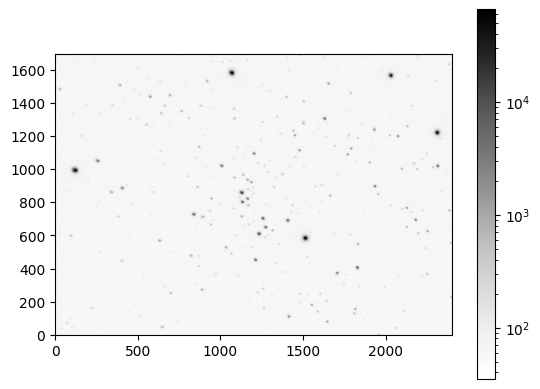

In [48]:
section1 = image_data[2300:4000, 100:2500]
plt.figure()
plt.imshow(section1,origin='lower',norm=LogNorm(),cmap='Greys')
plt.colorbar()
plt.show

It's actually a good idea to use the list of sources from the first image. Then you will have a measurement for the same positions (this is why we lined up the two filters first).

In [49]:
apertures_g = CircularAperture(positions,r=15.0) # This is the 1.5 FWHM as measured from the image using AIJ

In [50]:
annulus_aperture_g = CircularAnnulus(positions, r_in=27, r_out=41) # Set these to the ideal innder and outer apertures. 

<function matplotlib.pyplot.show(close=None, block=None)>

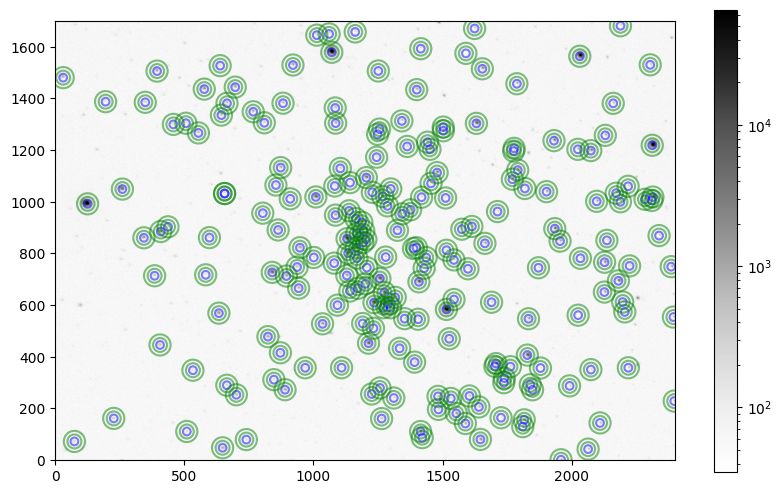

In [51]:
plt.figure(figsize=(10,6))
plt.imshow(section1,origin='lower',norm=LogNorm(),cmap='Greys',interpolation = 'nearest')
apertures_g.plot(color='blue',lw=1.5,alpha=0.5);
annulus_aperture_g.plot(color='green',lw=1.5,alpha=0.5)
plt.colorbar()
plt.show

In [52]:
star_data_g = aperture_photometry(section1,apertures_g)

In [53]:
bkg = aperture_photometry(section1,annulus_aperture_g)
bkg_area = annulus_aperture_g.area_overlap(section1)
aperture_area = apertures_g.area_overlap(section1)
bkg_total = (bkg['aperture_sum']/bkg_area)*aperture_area #deals with different sizes of the apertures

In [54]:
star_data['total_bkg_g']=bkg_total
star_data['bkg_area_g']=bkg_area
star_data['aperture_area_g']=aperture_area
star_data['star_count_g']=star_data_g['aperture_sum']-star_data['total_bkg_g']


for col in star_data.colnames:
    star_data[col].info.format='%.8g'

star_data.pprint(max_width=76)

 id  xcenter   ycenter  ... bkg_area_g aperture_area_g star_count_g
       pix       pix    ...                                        
--- --------- --------- ... ---------- --------------- ------------
  1 1958.4366 1.6027881 ...  1554.3154       416.30558    27862.811
  2 2063.2079 42.750891 ...  2990.7962       706.85835    25997.948
  3 648.35881 47.949685 ...  2990.7962       706.85835    95130.446
  4 74.725532 72.398721 ...  2990.7962       706.85835    18636.608
  5 740.21971 79.531223 ...  2990.7962       706.85835     12802.84
  6 1646.3792 80.342912 ...  2990.7962       706.85835    128725.01
  7 1421.0995 87.131377 ...  2990.7962       706.85835   -7326.2467
  8  509.7271 110.94459 ...  2990.7962       706.85835     15096.07
  9 1414.9008 110.88763 ...  2990.7962       706.85835     211324.2
 10 1810.2637 129.71849 ...  2990.7962       706.85835    50237.664
...       ...       ... ...        ...             ...          ...
205 2303.6905 1530.2794 ...  2990.7962       706

In [55]:
#Do both instrumental magnitudes

star_data_good=star_data[(star_data['star_count']>0) & (star_data['star_count_g']>0)]
star_data_good['inst_mag_r']=-2.5*np.log10(star_data_good['star_count'])
star_data_good['inst_mag_g']=-2.5*np.log10(star_data_good['star_count_g'])

star_data_good.pprint

<bound method Table.pprint of <QTable length=200>
  id   xcenter   ycenter  aperture_sum ... star_count_g inst_mag_r inst_mag_g
         pix       pix                 ...                                   
int64  float64   float64    float64    ...   float64     float64    float64  
----- --------- --------- ------------ ... ------------ ---------- ----------
    1 1958.4366 1.6027881    37945.369 ...    27862.811 -8.7896336 -11.112562
    2 2063.2079 42.750891    66659.504 ...    25997.948  -9.791449 -11.037348
    3 648.35881 47.949685     121748.6 ...    95130.446 -11.996655 -12.445799
    4 74.725532 72.398721    75615.939 ...    18636.608 -10.390915 -10.675917
    5 740.21971 79.531223    66287.576 ...     12802.84 -9.7135224 -10.268266
    6 1646.3792 80.342912    174629.36 ...    128725.01 -12.663179 -12.774157
    8  509.7271 110.94459    69507.579 ...     15096.07 -10.065246  -10.44716
    9 1414.9008 110.88763    79720.548 ...     211324.2 -10.818839 -13.312373
   11 1588.255

# Colour Magnitude Diagram

(-8.0, -16.0)

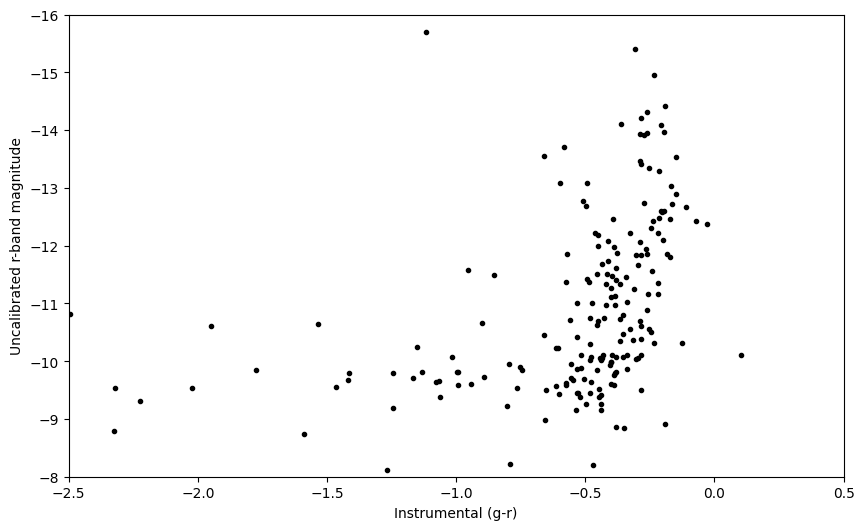

In [58]:
r = star_data_good['inst_mag_r']
grcolor = star_data_good['inst_mag_g'] - star_data_good['inst_mag_r']

plt.figure(figsize=(10,6))
plt.plot(grcolor, r, '.k')
plt.xlabel ('Instrumental (g-r)')
plt.ylabel ('Uncalibrated r-band magnitude')
plt.xlim(-2.5,0.5)
plt.ylim(-8,-16)
